# Wellenausbreitung in inhomogenen Medien: die Wave Propagation Method (WPM)

Die FFT-Propagatoren aus Notebook 01 setzen ein homogenes Medium voraus. Die
**Wave Propagation Method** von Brenner und Singer (`pyoptics.wpm`) erweitert die
Idee auf Medien mit ortsabhängigem Brechungsindex $n(x, y, z)$: Das Feld wird in
dünnen Scheiben $\Delta z$ propagiert. In jeder Scheibe wird es in ebene Wellen
zerlegt, und **jede ebene Welle wird an jedem Ort mit dem dortigen**
$k_z(x, y) = \sqrt{n(x, y)^2 k_0^2 - k_x^2 - k_y^2}$ **propagiert**:

$$U(x, y, z + \Delta z) = \sum_{k_x, k_y} \tilde U(k_x, k_y; z)\,
  e^{i(k_x x + k_y y)}\, e^{i k_z(x, y)\,\Delta z}.$$

Das ist keine einfache FFT mehr, sondern kostet $O(N_x^2 N_y^2)$ pro Schritt.
Für Probleme, die in $y$ invariant sind ($xz$-Schnitte durch Wellenleiter,
Zylinderlinsen, ...), benutzen wir wieder das Gitter mit zwei $y$-Zeilen aus
Notebook 01. Dann ist die WPM auch in Python-Notebooks schnell.

Hinweis: `wpm.pyx` ist eine Cython-Erweiterung und wird beim Installieren von
`pyoptics` kompiliert.

In [1]:
import time

import numpy as np
import matplotlib.pyplot as plt

from pyoptics.wpm import wpm_propagate
from pyoptics import propagators as prop
from pyoptics.utils import grid1d

plt.rcParams.update({"figure.dpi": 100, "image.origin": "lower", "font.size": 11})

wl = 1.0                 # Wellenlänge [µm]
k0 = 2*np.pi/wl
y2 = grid1d(-1, 1, 2)    # zwei y-Zeilen: in y invariantes Problem

def run_wpm(n_xz, u0, x, z_vals):
    """Propagiere u0(x) durch n(x, z) und gib das Feld auf allen z_vals zurück.
    n_xz(X, z) liefert den Index auf dem Gitter X für die Scheibe bei z."""
    n_func = lambda X, Y, z: n_xz(X, z)
    field = np.tile(u0, (2, 1)).astype(complex)
    out = [field[0]]
    for z, z_next in zip(z_vals[:-1], z_vals[1:]):
        field = wpm_propagate(n_func, field, x, y2, z, z_next - z, wl)
        out.append(field[0])
    return np.array(out)

def plot_xz(ax, U, x, z_vals, n_map=None, title="", xlim=None, gamma=1.0):
    I = np.abs(U)**2
    ax.imshow(((I/I.max())**gamma).T, extent=(z_vals[0], z_vals[-1], x[0], x[-1]), aspect="auto",
              cmap="inferno", interpolation="bilinear")
    if n_map is not None:
        ax.contour(z_vals, x, n_map.T, levels=np.unique(np.round(n_map, 4))[:-1] + 1e-4,
                   colors="w", linewidths=0.6, alpha=0.7)
    ax.set_xlabel("$z$ [µm]"); ax.set_ylabel("$x$ [µm]"); ax.set_title(title)
    if xlim:
        ax.set_ylim(*xlim)

## 1. Test: homogenes Medium

In einem homogenen Medium muss die WPM exakt das Ergebnis des
Rayleigh-Sommerfeld-Propagators (Transferfunktion mit $n$) liefern.

80 WPM-Schritte: 0.90 s, max. Abweichung zu RS: 4.3e-14


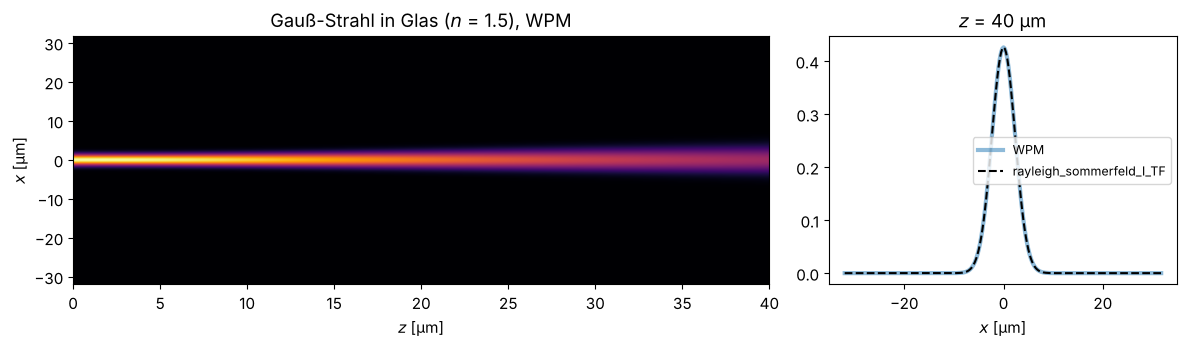

In [2]:
L, N = 64.0, 256
x = grid1d(-L/2, L/2, N)
u0 = np.exp(-x**2/2.0**2)
z_vals = np.linspace(0, 40, 81)

t0 = time.time()
U_wpm = run_wpm(lambda X, z: 1.5*np.ones_like(X), u0, x, z_vals)
t_wpm = time.time() - t0
U_rs, _, _ = prop.rayleigh_sommerfeld_I_TF(np.tile(u0, (2, 1)).astype(complex), x, y2, z_vals[-1], wl, n=1.5)
print(f"80 WPM-Schritte: {t_wpm:.2f} s, max. Abweichung zu RS: {np.abs(U_wpm[-1] - U_rs[0]).max():.1e}")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), gridspec_kw={"width_ratios": [2, 1]})
plot_xz(axes[0], U_wpm, x, z_vals, title="Gauß-Strahl in Glas ($n$ = 1.5), WPM")
axes[1].plot(x, np.abs(U_wpm[-1])**2, lw=3, alpha=0.5, label="WPM")
axes[1].plot(x, np.abs(U_rs[0])**2, "k--", label="rayleigh_sommerfeld_I_TF")
axes[1].set_xlabel("$x$ [µm]"); axes[1].set_title(f"$z$ = {z_vals[-1]:.0f} µm"); axes[1].legend(fontsize=9)
fig.tight_layout()

## 2. Gradientenindex-Linse (GRIN)

Ein parabolisches Indexprofil $n(x) = n_0\,(1 - g^2 x^2/2)$ wirkt wie eine
kontinuierliche Folge schwacher Linsen. Strahlen schwingen sinusförmig um die
Achse, $x(z) = x_0\cos(gz)$, mit der *Pitch-Länge* $P = 2\pi/g$. Ein Gauß-Strahl
mit dem Radius $w_m = \sqrt{2/(k_0 n_0 g)}$ ist der Grundmode des Profils und läuft
unverändert. Ein schmalerer Strahl "atmet" mit der Periode $P/2$, ein
versetzter pendelt wie der Strahl der geometrischen Optik. (Dargestellt ist
$I^{0.6}$, damit die schwachen Teile sichtbar bleiben.)

Der versetzte Strahl pendelt etwas langsamer als der paraxiale Strahl
$x_0\cos(gz)$: Bei 8 µm Auslenkung ist er nicht mehr streng paraxial.

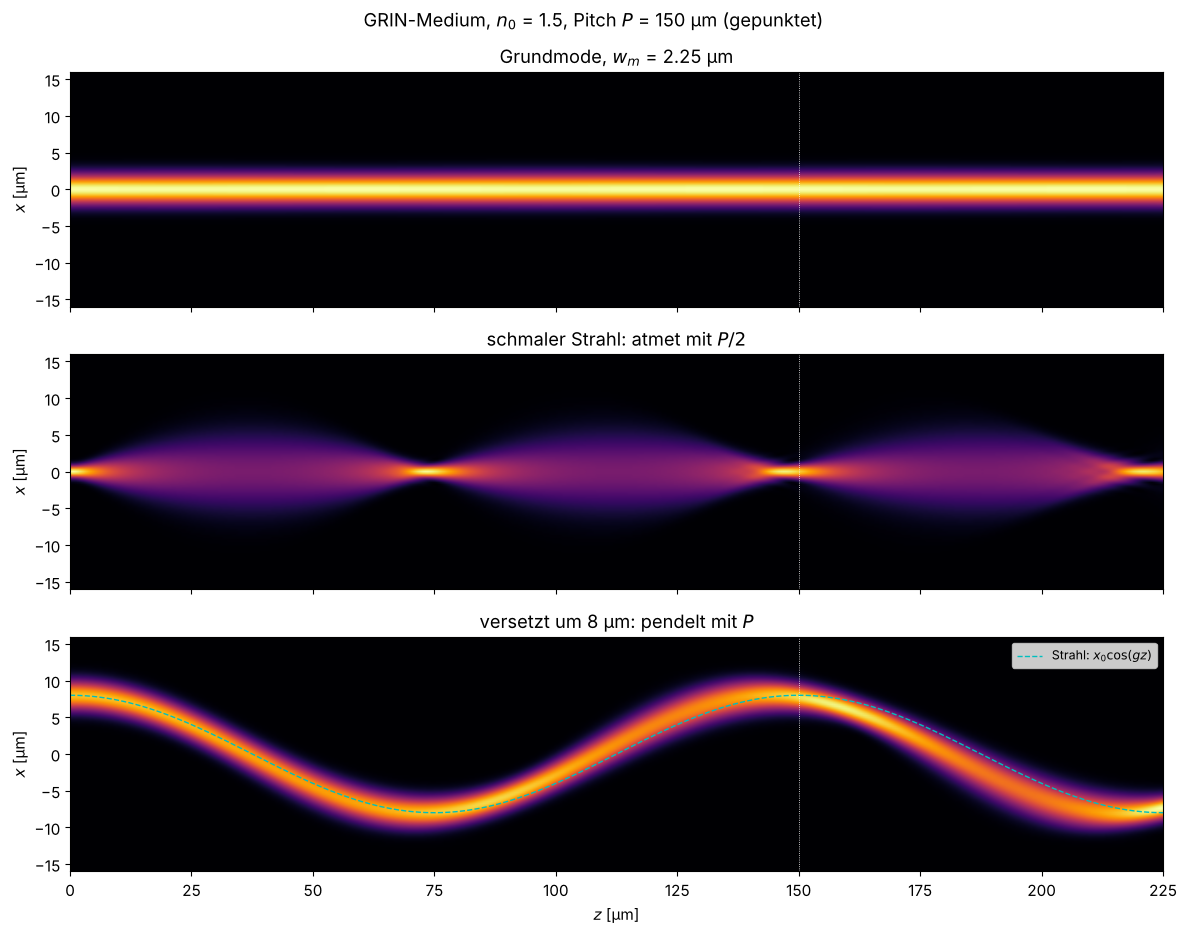

In [3]:
n0, P = 1.5, 150.0
g = 2*np.pi/P
# Profil am Rand bei n = 1.3 abschneiden, sonst fiele der Index am Fensterrand unter 1:
n_grin = lambda X, z: np.maximum(n0*(1 - g**2*X**2/2), 1.3)
w_m = np.sqrt(2/(k0*n0*g))
z_vals = np.linspace(0, 1.5*P, 451)

beams = ((np.exp(-x**2/w_m**2), f"Grundmode, $w_m$ = {w_m:.2f} µm"),
         (np.exp(-x**2/(w_m/2.5)**2), "schmaler Strahl: atmet mit $P/2$"),
         (np.exp(-(x - 8)**2/w_m**2), "versetzt um 8 µm: pendelt mit $P$"))
fig, axes = plt.subplots(3, 1, figsize=(12, 9.5), sharex=True)
for ax, (u, title) in zip(axes, beams):
    U = run_wpm(n_grin, u, x, z_vals)
    plot_xz(ax, U, x, z_vals, title=title, xlim=(-16, 16), gamma=0.6)
    for m in range(1, 2):
        ax.axvline(m*P, color="w", lw=0.6, ls=":")
axes[2].plot(z_vals, 8*np.cos(g*z_vals), "c--", lw=1, label="Strahl: $x_0\\cos(gz)$")
axes[2].legend(loc="upper right", fontsize=9)
for ax in axes[:2]:
    ax.set_xlabel("")
fig.suptitle(f"GRIN-Medium, $n_0$ = {n0}, Pitch $P$ = {P:.0f} µm (gepunktet)")
fig.tight_layout()

## 3. Stufenindex-Wellenleiter

Ein Kern mit höherem Index hält Licht durch Totalreflexion fest. Im Wellenbild:
Der Kern trägt geführte Moden, deren Feld im Mantel evaneszent abklingt. Ein
Gauß-Strahl, der nicht genau zum Grundmode passt, regt mehrere Moden an, die mit
verschiedenen Ausbreitungskonstanten laufen und miteinander schweben. Ohne Kern
(rechts) beugt der Strahl einfach auseinander.

NA = 0.344, V-Parameter (halbe Kernbreite) = 6.49 -> etwa 5 geführte Moden


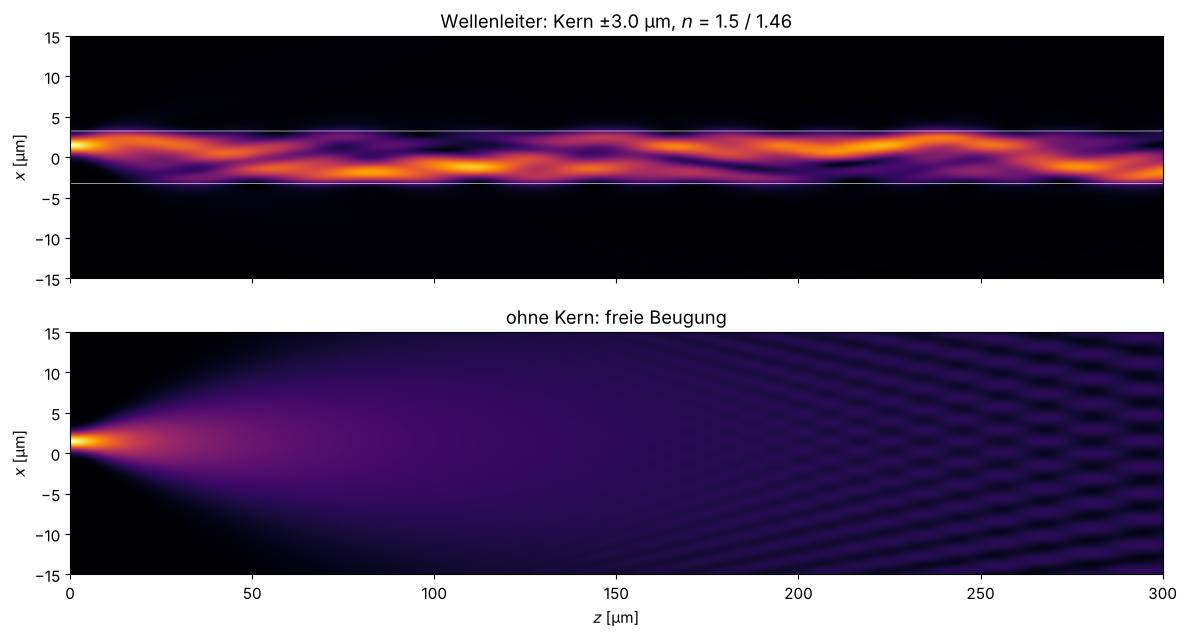

In [4]:
core, n_core, n_clad = 3.0, 1.50, 1.46
n_wg = lambda X, z: np.where(np.abs(X) <= core, n_core, n_clad)
NA_wg = np.sqrt(n_core**2 - n_clad**2)
V = k0*core*NA_wg
print(f"NA = {NA_wg:.3f}, V-Parameter (halbe Kernbreite) = {V:.2f} -> etwa {int(2*V/np.pi) + 1} geführte Moden")
z_vals = np.linspace(0, 300, 601)
u_in = np.exp(-(x - 1.5)**2/1.2**2)   # schmal und leicht versetzt: regt mehrere Moden an

U_wg = run_wpm(n_wg, u_in, x, z_vals)
U_free = run_wpm(lambda X, z: n_clad*np.ones_like(X), u_in, x, z_vals)
n_map = np.array([n_wg(x, z) for z in z_vals])

fig, axes = plt.subplots(2, 1, figsize=(12, 6.5), sharex=True)
plot_xz(axes[0], U_wg, x, z_vals, n_map=n_map, title=f"Wellenleiter: Kern ±{core} µm, $n$ = {n_core} / {n_clad}",
        xlim=(-15, 15), gamma=0.6)
plot_xz(axes[1], U_free, x, z_vals, title="ohne Kern: freie Beugung", xlim=(-15, 15), gamma=0.6)
axes[0].set_xlabel("")
fig.tight_layout()

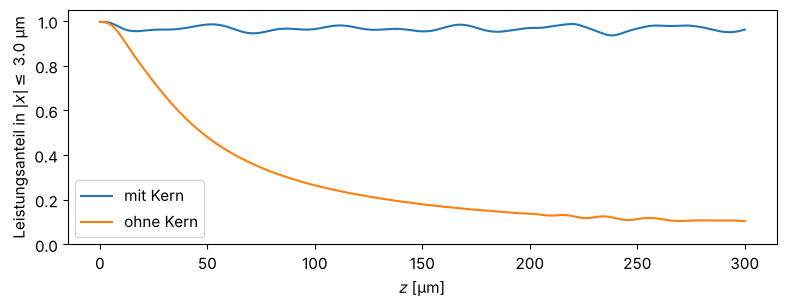

In [5]:
P_core = [np.sum(np.abs(U[np.abs(x) <= core])**2)/np.sum(np.abs(U)**2) for U in U_wg]
P_free = [np.sum(np.abs(U[np.abs(x) <= core])**2)/np.sum(np.abs(U)**2) for U in U_free]
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.plot(z_vals, P_core, label="mit Kern")
ax.plot(z_vals, P_free, label="ohne Kern")
ax.set_xlabel("$z$ [µm]"); ax.set_ylabel("Leistungsanteil in $|x| \\leq$ " + f"{core} µm")
ax.set_ylim(0, 1.05); ax.legend()
fig.tight_layout()

Ein Teil der Leistung geht am Anfang verloren: Er gehört zu Strahlungsmoden,
die nicht geführt werden und seitlich abstrahlen. (Am Fensterrand tritt dieses
Licht wegen der periodischen Randbedingungen der Ebene-Wellen-Zerlegung auf der
anderen Seite wieder ein; für längere Strecken bräuchte man absorbierende Ränder.)

## 4. Eine dicke Zylinderlinse

Zum Schluss ein Fall, für den die WPM gemacht ist: ein großer Indexsprung an
einer gekrümmten Fläche. Eine plankonvexe Zylinderlinse aus Glas ($n = 1.5$) mit
Krümmungsradius $R$ hat die Brennweite $f = R/(n-1)$, gemessen von der
Hauptebene, die bei einer plankonvexen Linse am Scheitel der gekrümmten Fläche
liegt. Die Apertur ist mit $\pm 30$ µm bei $R = 60$ µm aber alles andere als paraxial.
Die WPM zeigt den Fokus samt sphärischer Aberration: Randstrahlen schneiden die
Achse zu früh, das Intensitätsmaximum liegt deutlich vor dem paraxialen Fokus,
und vor dem Fokus bildet sich eine Kaustik.

699 WPM-Schritte mit N = 512: 27.3 s
paraxialer Fokus bei z = 135.0 µm, Intensitätsmaximum bei z = 121.7 µm


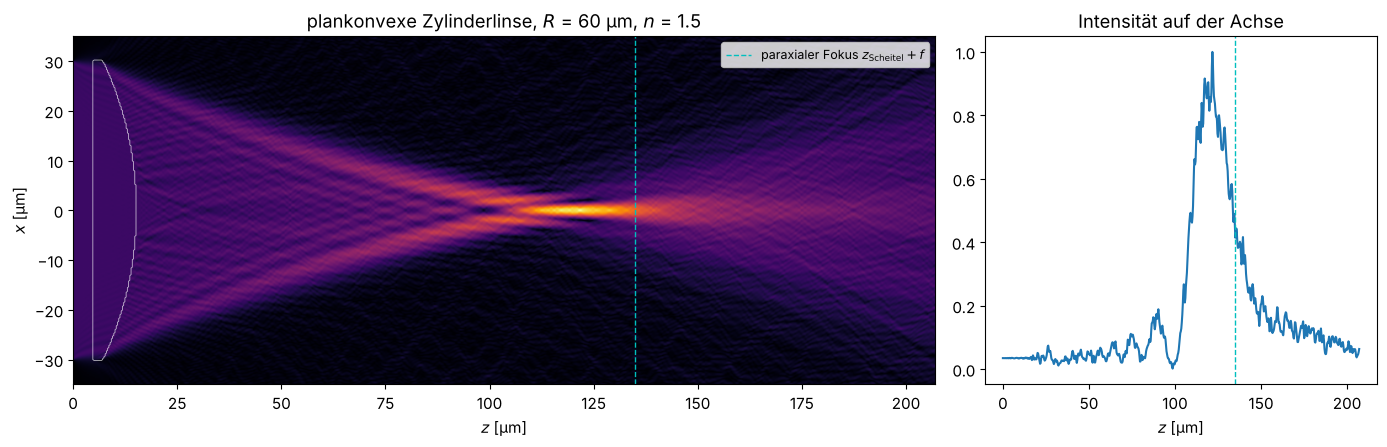

In [6]:
L4, N4 = 96.0, 512
x4 = grid1d(-L4/2, L4/2, N4)
R_lens, n_lens, z_front, half_ap = 60.0, 1.5, 5.0, 30.0
sag = R_lens - np.sqrt(np.maximum(R_lens**2 - x4**2, 0))
t_center = R_lens - np.sqrt(R_lens**2 - half_ap**2) + 2.0   # Mittendicke
z_vertex = z_front + t_center   # Scheitel der gekrümmten Rückseite

def n_lens_func(X, z):
    # plane Vorderseite bei z_front, gekrümmte Rückseite: z <= z_vertex - sag(x)
    s = R_lens - np.sqrt(np.maximum(R_lens**2 - X**2, 0))
    inside = (z >= z_front) & (z <= z_vertex - s) & (np.abs(X) <= half_ap)
    return np.where(inside, n_lens, 1.0)

f = R_lens/(n_lens - 1)
z_vals = np.linspace(0, z_vertex + 1.6*f, 700)
u_plane = np.where(np.abs(x4) <= half_ap, 1.0, 0.0)*np.exp(-(x4/40)**8)  # weich begrenzte ebene Welle
t0 = time.time()
U_lens = run_wpm(n_lens_func, u_plane, x4, z_vals)
print(f"{len(z_vals) - 1} WPM-Schritte mit N = {N4}: {time.time() - t0:.1f} s")
n_map = np.array([n_lens_func(x4, z) for z in z_vals])

fig, axes = plt.subplots(1, 2, figsize=(14, 4.6), gridspec_kw={"width_ratios": [2.2, 1]})
plot_xz(axes[0], U_lens, x4, z_vals, n_map=n_map, title=f"plankonvexe Zylinderlinse, $R$ = {R_lens:.0f} µm, $n$ = {n_lens}",
        xlim=(-35, 35), gamma=0.5)
axes[0].axvline(z_vertex + f, color="c", ls="--", lw=1, label="paraxialer Fokus $z_\\mathrm{Scheitel} + f$")
axes[0].legend(loc="upper right", fontsize=9)
I_axis = np.abs(U_lens[:, N4//2])**2
axes[1].plot(z_vals, I_axis/I_axis.max())
axes[1].axvline(z_vertex + f, color="c", ls="--", lw=1)
axes[1].set_xlabel("$z$ [µm]"); axes[1].set_title("Intensität auf der Achse")
fig.tight_layout()
z_peak = z_vals[np.argmax(I_axis)]
print(f"paraxialer Fokus bei z = {z_vertex + f:.1f} µm, Intensitätsmaximum bei z = {z_peak:.1f} µm")